# EDA on Retail Sales Data

## Loading and Inspecting the Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/retail_sales_dataset.csv")

In [ ]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [ ]:
df.shape

(1000, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [ ]:
df.isnull().sum()

,0
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


**Observations:** The dataset has 1,000 transactions and 9 columns, with no missing values. Date is stored as text and will be converted to a datetime type for time-series analysis. There are no product names, only 3 categories.

## Preparing the Date Column

Date is stored as text, so it was converted to datetime. Month and Quarter columns were created for the time-series analysis.

In [ ]:
df["Date"] = pd.to_datetime(df["Date"])

In [ ]:
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

In [ ]:
df[["Date", "Month", "Quarter"]].head()

,Date,Month,Quarter
0,2023-11-24,2023-11,2023Q4
1,2023-02-27,2023-02,2023Q1
2,2023-01-13,2023-01,2023Q1
3,2023-05-21,2023-05,2023Q2
4,2023-05-06,2023-05,2023Q2


In [ ]:
df["Month"].value_counts().sort_index()

,count
Month,
2023-01,76
2023-02,85
2023-03,73
2023-04,86
2023-05,105
2023-06,77
2023-07,72
2023-08,94
2023-09,65


## Descriptive Statistics

Mean, median, mode and standard deviation were calculated for all numerical columns.

In [ ]:
num_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
df[num_cols].agg(["mean", "median", "std"])

,Age,Quantity,Price per Unit,Total Amount
mean,41.39200,2.514000,179.890000,456.000000
median,42.00000,3.000000,50.000000,135.000000
std,13.68143,1.132734,189.681356,559.997632


In [ ]:
df[num_cols].mode()

,Age,Quantity,Price per Unit,Total Amount
0,43,4.0,50.0,50.0
1,64,NaN,NaN,NaN


**Observations:** Mean Total Amount (456) is far above the median (135), so a minority of high-priced orders pull revenue up. Age has two modes (43 and 64), showing a wide spread of customer ages (18 to 64). The most common quantity per order is 4, and the most common price per unit is 50.

## Time Series Analysis

Monthly and quarterly sales trends. Two transactions dated January 2024 were excluded, because a single day would appear as a false collapse in sales.

In [ ]:
df_2023 = df[df["Date"] < "2024-01-01"]

In [ ]:
monthly_sales = df_2023.groupby("Month")["Total Amount"].sum()
monthly_sales

,Total Amount
Month,
2023-01,35450
2023-02,44060
2023-03,28990
2023-04,33870
2023-05,53150
2023-06,36715
2023-07,35465
2023-08,36960
2023-09,23620


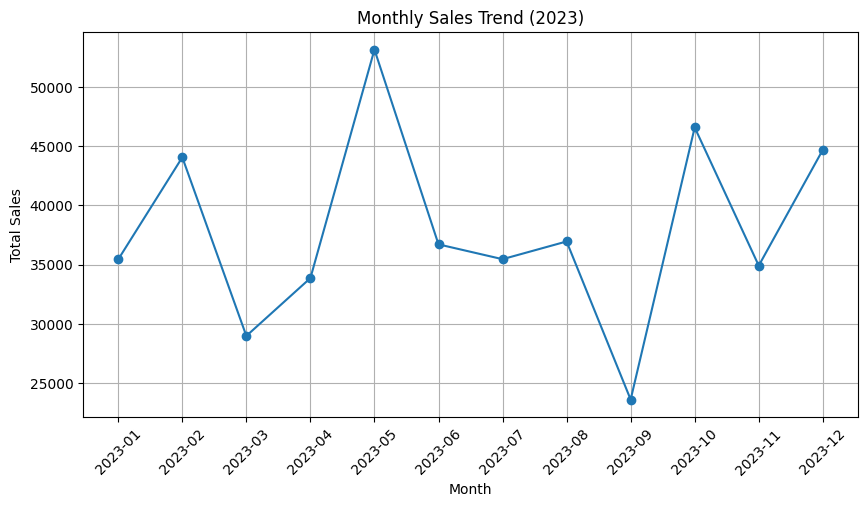

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend (2023)")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [ ]:
quarterly_sales = df_2023.groupby("Quarter")["Total Amount"].sum()
quarterly_sales

,Total Amount
Quarter,
2023Q1,108500
2023Q2,123735
2023Q3,96045
2023Q4,126190


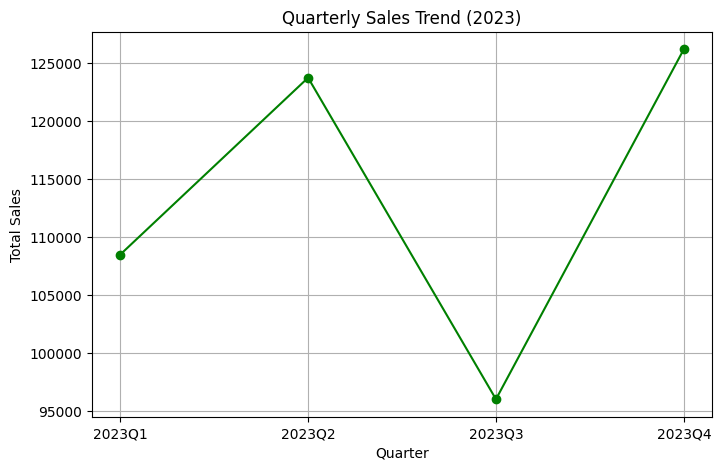

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(quarterly_sales.index.astype(str), quarterly_sales.values, marker="o", color="green")
plt.title("Quarterly Sales Trend (2023)")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.grid(True)
plt.show()

**Observations (monthly):** Sales peaked in May (about 53,150) and were lowest in September (about 23,620). Sales fluctuate month to month rather than rising steadily.

**Observations (quarterly):** Q4 was the strongest quarter (about 126,190) and Q3 the weakest (about 96,045), a drop of roughly 24% from Q4.

## Customer Demographics

Distribution of customer age groups and gender breakdown.

In [ ]:
df["Age Group"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 64], labels=["18-25", "26-35", "36-45", "46-55", "56-64"])

In [ ]:
age_counts = df["Age Group"].value_counts().sort_index()
age_counts

,count
Age Group,
18-25,169
26-35,205
36-45,202
46-55,229
56-64,195


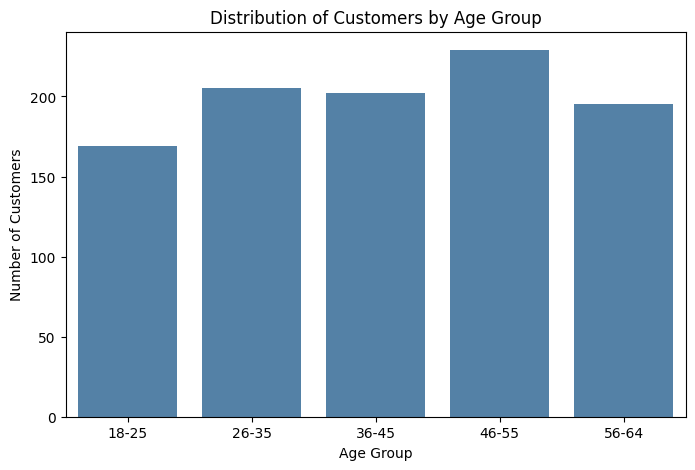

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x=age_counts.index, y=age_counts.values, color="steelblue")
plt.title("Distribution of Customers by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
gender_counts = df["Gender"].value_counts()
gender_counts

,count
Gender,
Female,510
Male,490


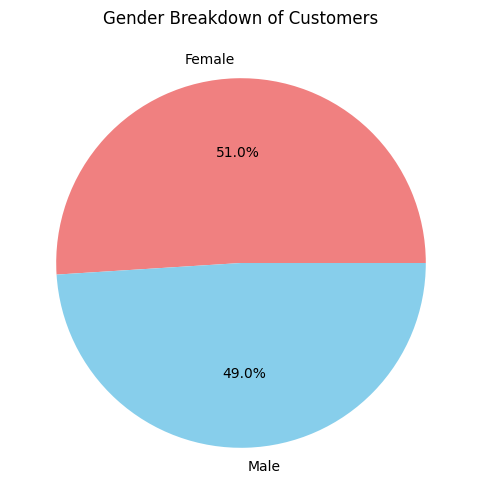

In [ ]:
plt.figure(figsize=(6, 6))
plt.pie(gender_counts.values, labels=gender_counts.index, autopct="%1.1f%%", colors=["lightcoral", "skyblue"])
plt.title("Gender Breakdown of Customers")
plt.show()

In [ ]:
df.groupby("Gender")["Total Amount"].agg(["sum", "mean"])

,sum,mean
Gender,,
Female,232840,456.549020
Male,223160,455.428571


In [ ]:
df.groupby("Age Group")["Total Amount"].sum()

/tmp/ipykernel_5481/4217949873.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("Age Group")["Total Amount"].sum()


,Total Amount
Age Group,
18-25,84550
26-35,98480
36-45,91870
46-55,100690
56-64,80410


**Observations:** The 46-55 age group is the largest (229 customers) and generates the most revenue (100,690), while 18-25 is the smallest group (169). Customers are almost evenly split by gender (51% female, 49% male), and average spend per transaction is almost identical (about 456), so gender does not appear to drive spending.

## Product Analysis

The dataset contains no individual product names, only 3 product categories and 5 price points. A top 10 product ranking is therefore not possible. Instead, products are analysed at category level, and the 5 price points are treated as product tiers and ranked by units sold and revenue.

In [ ]:
category_summary = df.groupby("Product Category").agg(
    Revenue=("Total Amount", "sum"),
    Units_Sold=("Quantity", "sum"),
    Transactions=("Transaction ID", "count"),
    Avg_Order_Value=("Total Amount", "mean")
).sort_values("Revenue", ascending=False)
category_summary

,Revenue,Units_Sold,Transactions,Avg_Order_Value
Product Category,,,,
Electronics,156905,849,342,458.786550
Clothing,155580,894,351,443.247863
Beauty,143515,771,307,467.475570


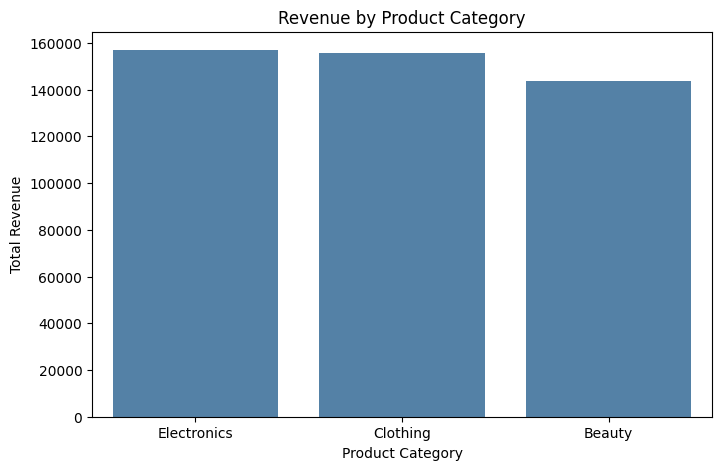

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x=category_summary.index, y=category_summary["Revenue"], color="steelblue")
plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.show()

In [ ]:
tier_summary = df.groupby("Price per Unit").agg(
    Units_Sold=("Quantity", "sum"),
    Revenue=("Total Amount", "sum")
).sort_values("Units_Sold", ascending=False)
tier_summary

,Units_Sold,Revenue
Price per Unit,,
50,534,26700
25,522,13050
300,518,155400
500,495,247500
30,445,13350


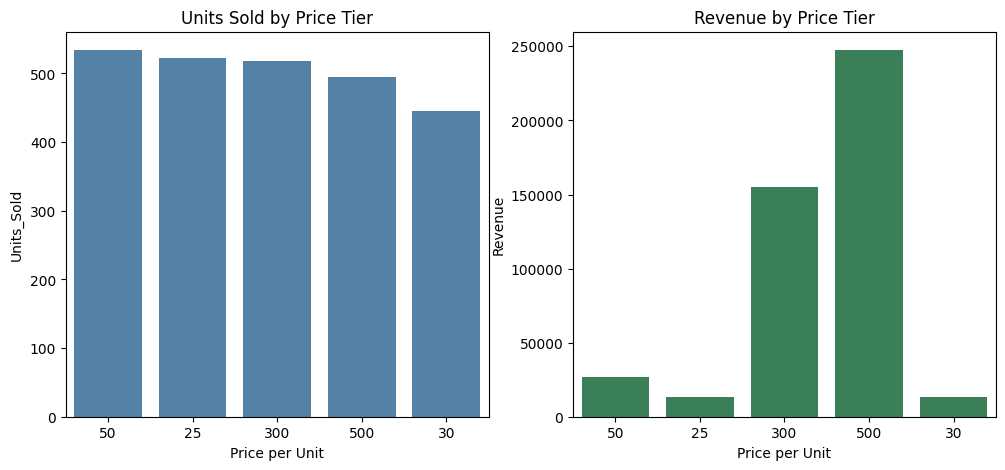

In [ ]:
tier_summary.index = tier_summary.index.astype(str)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(x=tier_summary.index, y=tier_summary["Units_Sold"], ax=axes[0], color="steelblue")
axes[0].set_title("Units Sold by Price Tier")
axes[0].set_xlabel("Price per Unit")
sns.barplot(x=tier_summary.index, y=tier_summary["Revenue"], ax=axes[1], color="seagreen")
axes[1].set_title("Revenue by Price Tier")
axes[1].set_xlabel("Price per Unit")
plt.show()

**Observations:** Electronics (156,905) and Clothing (155,580) generate nearly equal revenue, with Beauty about 8% behind. Units sold are similar across all five price tiers, yet the 500 tier alone generates about 54% of total revenue, and the 300 and 500 tiers together about 88%. Revenue is driven by high-priced items rather than sales volume.

## Correlation Analysis

A correlation matrix between the numerical variables. Transaction ID was excluded because it is only a label, so its correlation with anything would be meaningless.

In [ ]:
corr = df[["Age", "Quantity", "Price per Unit", "Total Amount"]].corr()
corr

,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


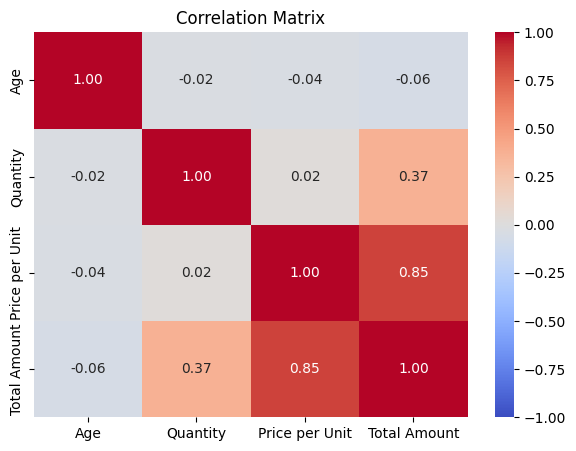

In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

**Observations:** Price per Unit is strongly correlated with Total Amount (0.85), while Quantity is only moderately correlated (0.37), so revenue is driven mainly by price rather than the number of items bought. Age shows almost no correlation with any variable, so age alone does not predict spending.

## Additional Insight: Category Preferences by Age Group

Revenue was broken down by age group and product category to look for differences in preferences that the overall totals hide.

In [ ]:
pivot = df.pivot_table(index="Age Group", columns="Product Category", values="Total Amount", aggfunc="sum")
pivot

/tmp/ipykernel_5481/443078160.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  pivot = df.pivot_table(index="Age Group", columns="Product Category", values="Total Amount", aggfunc="sum")


Product Category,Beauty,Clothing,Electronics
Age Group,,,
18-25,31280,26510,26760
26-35,31240,39975,27265
36-45,28405,29550,33915
46-55,34720,30485,35485
56-64,17870,29060,33480


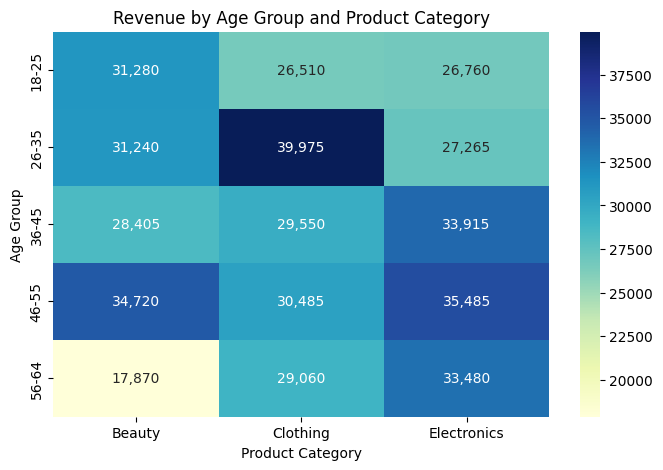

In [ ]:
plt.figure(figsize=(8, 5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlGnBu")
plt.title("Revenue by Age Group and Product Category")
plt.show()

**Observations:** Overall category revenue looks similar, but preferences vary strongly by age. Clothing peaks among 26-35 year olds (39,975), Beauty falls to about half its usual level among 56-64 year olds (17,870), and Electronics is strongest from age 36 upward. This suggests marketing should be targeted by age group rather than applied evenly.

## Conclusion

This analysis examined 1,000 retail transactions from January to December 2023 across three product categories (Beauty, Clothing, Electronics). The data had no missing values or duplicates. Key findings and recommendations follow.

### Key Findings
- Total revenue is driven by price, not volume. Units sold are similar across all five price tiers, yet the 500 tier generates about 54% of revenue, and the 300 and 500 tiers together about 88%.
- Sales are uneven across the year. May was the strongest month (53,150) and September the weakest (23,620). Q4 was the strongest quarter (126,190) and Q3 the weakest (96,045).
- Customers are evenly split by gender (51% female, 49% male), and average spend per transaction is almost identical (about 456).
- Category preferences differ by age. Clothing peaks among 26-35 year olds, Electronics is strongest from age 36 upward, and Beauty falls to about half its usual level among 56-64 year olds.

### Recommendations
1. **Prioritise premium products.** Items priced at 300 and 500 bring in about 88% of revenue while selling about the same number of units as cheaper items. Feature them in promotions, bundles and store placement, and avoid heavy discounting on the premium tiers.
2. **Target marketing by age group instead of using one message for everyone.** Direct Clothing campaigns at 26-35 year olds and Electronics campaigns at customers aged 36 and above. Investigate why Beauty revenue halves among 56-64 year olds, for example through a product range review or a targeted offer, before spending more there.
3. **Plan around seasonality.** Increase stock and staffing ahead of Q4, the strongest quarter. Run a promotion in the Q3 slump, especially September, to lift the weakest period.
4. **Use gender-neutral marketing and pricing.** Men and women spend almost the same per transaction, so there is no evidence to justify gender-specific pricing or campaigns. Segment by age instead.
5. **Grow Beauty traffic.** Beauty has the highest average order value (467.48) but the fewest transactions (307), so the opportunity lies in reaching more customers, not in raising prices.
6. **Retain the 46-55 group.** This is the largest revenue source, and look for growth among 18-25 and 26-35 customers, who spend the most per transaction (500.3 and 480.4). Increasing their numbers would likely raise revenue faster than further targeting the 46-55 group.

### Limitations
The dataset covers one year and 1,000 transactions, with no individual product names or store locations. Recommendations should be tested with further data before large decisions are made.